# Séries temporelles : évolution du prix médian au m² en France

**Contributeurs :** Cécile · **Date :** 25/10/2026

## Objectif

Cette partie complète la modélisation principale (une ligne par bassin de vie et par année). Ici, on s'intéresse uniquement à la dimension temporelle du marché, sans tenir compte de la localisation : on suit le prix médian au m² de toute la France, mois par mois.

Question posée : **la série des prix suffit-elle, à elle seule, à prévoir l'évolution des prix un an à l'avance ?** On ajoute ensuite les deux seules autres informations mensuelles dont on dispose : le volume de ventes, puis le taux des crédits immobiliers.

| Élément | Choix retenu |
|---|---|
| Cible | Prix médian au m² national du mois, recalculé à partir des ventes. |
| Population | Ventes de DVF+ résidentiel : ventes classiques d'une seule maison ou d'un seul appartement, VEFA, DOM et Alsace-Moselle exclus ; prix au m² entre 50 et 50 000 €. |
| Biens | Maisons et appartements suivis séparément, avec les mêmes hyperparamètres. |
| Horizon | Un an : les 12 mois de l'année suivante sont prévus d'un seul coup. |
| Évaluation | Validation croisée temporelle sur 5 plis (prévision de 2020, 2021, 2022, 2023 et 2024), puis test final sur 2025, chargée seulement à la fin. |
| Références | Prévision naïve (dernier mois connu répété) et prévision naïve saisonnière (mêmes mois de l'année précédente). |

## Préparation des séries

Prix médian au m² et nombre de ventes par mois, de 2014 à 2024, pour les maisons et les appartements ; taux des crédits immobiliers mensuel (Banque de France).

maisons : 132 mois | valeurs manquantes : 0 | ventes par mois : 17500 à 71478
appartements : 132 mois | valeurs manquantes : 0 | ventes par mois : 12450 à 46715


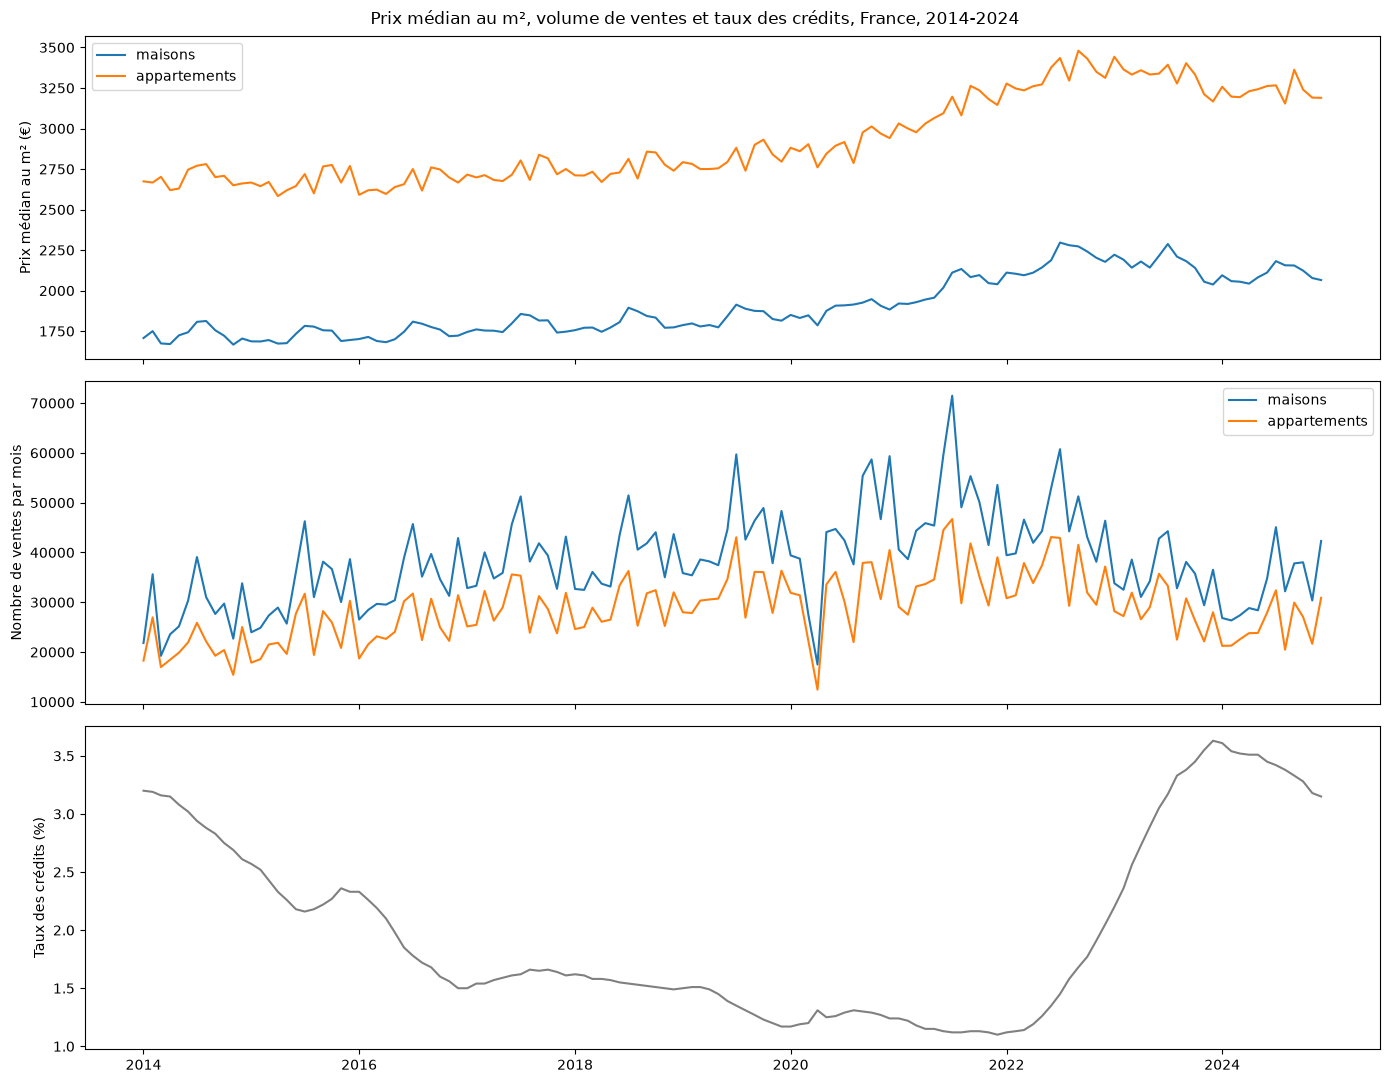

In [1]:
# Préparation : prix médian au m² et volume de ventes par mois (2014-2024), taux des crédits mensuel
import itertools
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from sklearn.model_selection import TimeSeriesSplit
from statsmodels.tsa.api import VAR
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller

# config.py est à la racine du projet : on remonte les dossiers jusqu'à le trouver
racine = Path.cwd()
while not (racine / "config.py").exists() and racine != racine.parent:
    racine = racine.parent
sys.path.insert(0, str(racine))
from config import DATA_OUT

TYPES = ["maisons", "appartements"]
ITERATIONS = 200   # itérations maximales des estimations (50 par défaut, souvent insuffisant)
HORIZON = 12       # on prévoit une année entière d'un seul coup
decoupage = TimeSeriesSplit(n_splits=5, test_size=HORIZON)   # 5 plis : prévision de 2020 à 2024


def series_mensuelles(annees):
    """Prix médian au m² et nombre de ventes par mois et par type de bien (mêmes règles que les tables cibles)."""
    v = pd.read_parquet(DATA_OUT / "dvf_plus_residentiel.parquet",
                        columns=["anneemut", "moismut", "libtypbien", "valeurfonc", "sbati"],
                        filters=[("anneemut", "in", annees)])
    v["prix_m2"] = v["valeurfonc"] / v["sbati"]
    v = v[v["valeurfonc"].notna() & (v["valeurfonc"] > 0) & v["prix_m2"].between(50, 50000)].copy()
    v["type_bien"] = v["libtypbien"].map({"UNE MAISON": "maisons", "UN APPARTEMENT": "appartements"})
    v["mois"] = pd.to_datetime(pd.DataFrame({"year": v["anneemut"], "month": v["moismut"], "day": 1}))
    return v.groupby(["type_bien", "mois"])["prix_m2"].agg(volume="count", prix="median")


# 2014-2024 seulement : 2025 est réservée au test final
mensuel = series_mensuelles(list(range(2014, 2025)))
prix = {t: mensuel.loc[t, "prix"].asfreq("MS") for t in TYPES}
volume = {t: mensuel.loc[t, "volume"].asfreq("MS") for t in TYPES}

# Taux des crédits mensuel (bloc 11 de la préparation)
taux_m = pd.read_parquet(DATA_OUT / "taux_credit_mois.parquet")
taux = pd.Series(taux_m["taux"].values, index=pd.to_datetime(
    pd.DataFrame({"year": taux_m["annee"], "month": taux_m["mois"], "day": 1}))).asfreq("MS")

for t in TYPES:
    print(f"{t} : {len(prix[t])} mois | valeurs manquantes : {prix[t].isna().sum()} | "
          f"ventes par mois : {volume[t].min()} à {volume[t].max()}")

# Les trois séries mensuelles, 2014-2024
fig, axes = plt.subplots(3, 1, figsize=(14, 11), sharex=True)
for t in TYPES:
    axes[0].plot(prix[t], label=t)
    axes[1].plot(volume[t], label=t)
axes[2].plot(taux.loc["2014":"2024"], color="grey")
for ax, titre in zip(axes, ["Prix médian au m² (€)", "Nombre de ventes par mois", "Taux des crédits (%)"]):
    ax.set_ylabel(titre)
axes[0].legend()
axes[1].legend()
fig.suptitle("Prix médian au m², volume de ventes et taux des crédits, France, 2014-2024")
plt.tight_layout()
plt.show()

**Lecture des séries**

Chaque médiane mensuelle repose sur au moins 12 450 ventes : les séries nationales sont peu bruitées.
- **Prix** : stable de 2014 à 2016, il augmente à partir de 2017, accélère de 2020 à 2022, atteint un sommet à l'été 2022, baisse en 2023 puis se stabilise en 2024. Un pic revient chaque été.
- **Volume de ventes** : très saisonnier (pic chaque été), il chute au printemps 2020 (premier confinement), atteint un sommet en 2021, puis recule à partir du second semestre 2022 : le pic d'été des maisons passe d'environ 71 000 ventes en 2021 à environ 45 000 en 2024. Le volume baisse alors que le prix est encore à son sommet.
- **Taux des crédits** : il baisse jusqu'à 1,1-1,3 % en 2019-2021, remonte fortement de 2022 à fin 2023 (environ 3,6 %), puis redescend au cours de 2024.

## 1. Le prix seul suffit-il à prévoir les prix ?

Modèle SARIMA sur le log du prix (différenciation d'ordre 1, saisonnalité de 12 mois). Les ordres sont choisis par le BIC, sur 2014-2023, avec une même grille pour les deux types de bien : on retient l'ordre dont la somme des BIC des maisons et des appartements est la plus petite. Le modèle est ensuite évalué par validation croisée temporelle : à chaque pli, il est entraîné sur toutes les années précédentes et prévoit les 12 mois de l'année suivante.

,,BIC maisons + appartements
ordre,saison,
"(1, 1, 0)","(1, 0, 1, 12)",-1278.6
"(0, 1, 1)","(1, 0, 1, 12)",-1278.4
"(2, 1, 0)","(1, 0, 1, 12)",-1272.9
"(0, 1, 2)","(1, 0, 1, 12)",-1272.3
"(1, 1, 1)","(1, 0, 1, 12)",-1271.8


Ordre retenu : SARIMA(1, 1, 0)(1, 0, 1, 12)


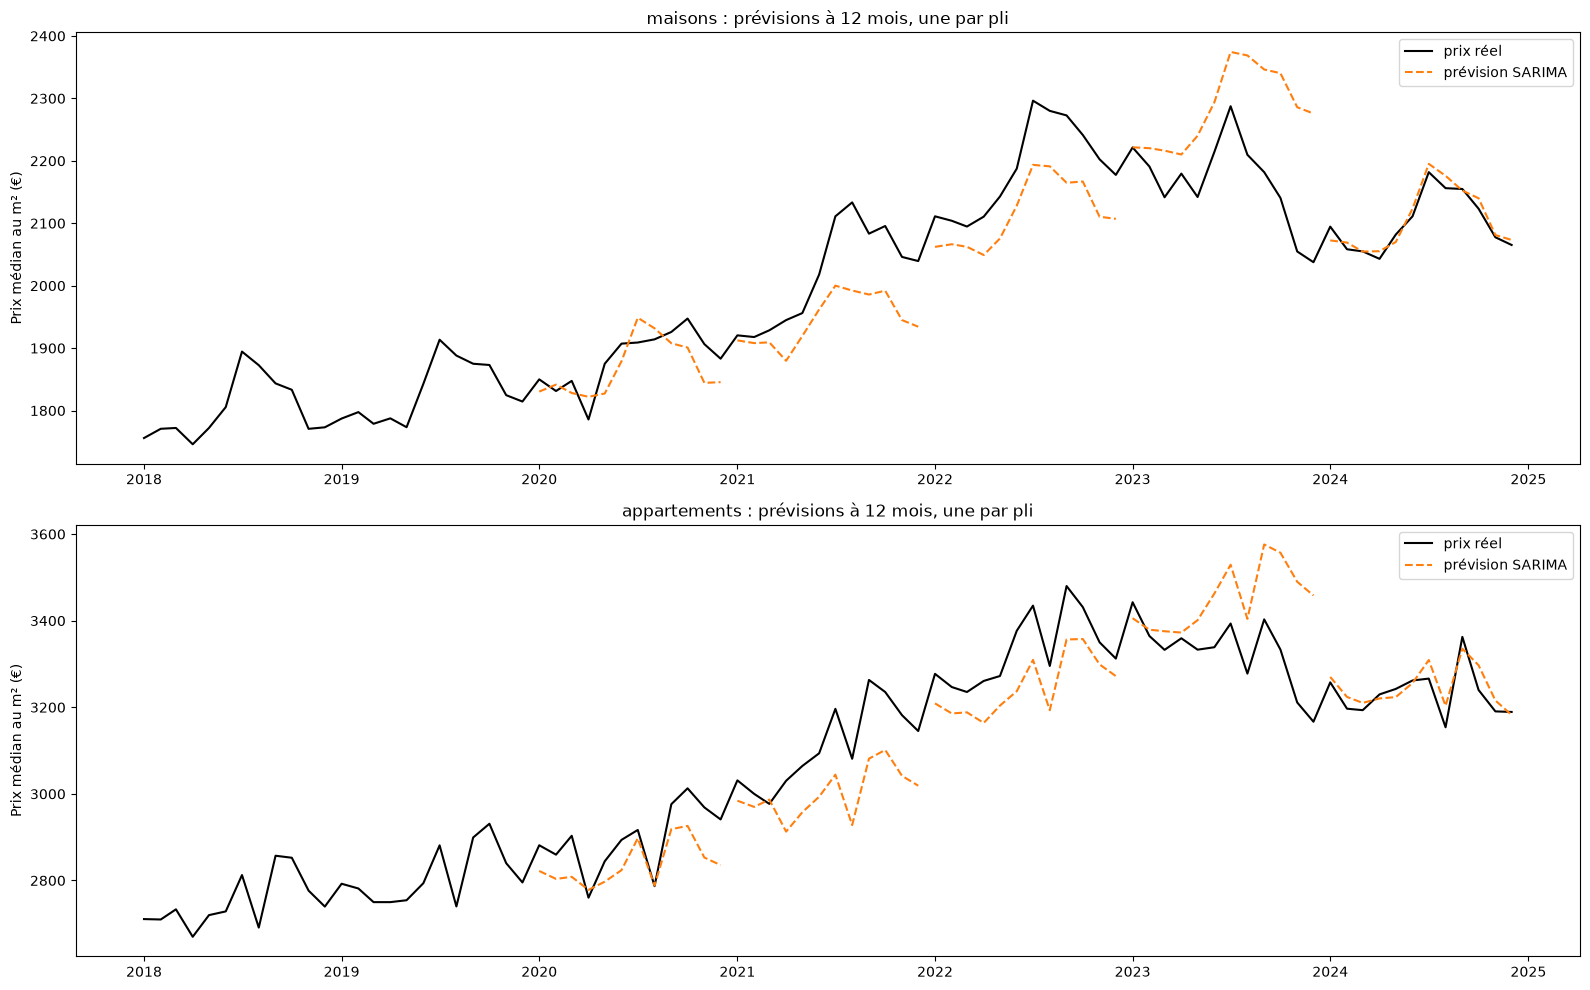

,type de bien,année prévue,MAE modèle (€/m²),MAPE modèle (%),MAE naïf (€/m²),MAE naïf saisonnier (€/m²),convergé
0,maisons,2020,31.9,1.7,72.2,53.3,True
1,maisons,2021,71.2,3.5,133.1,134.3,True
2,maisons,2022,70.3,3.2,145.6,168.8,True
3,maisons,2023,116.0,5.4,51.1,74.9,True
4,maisons,2024,11.1,0.5,62.6,75.0,True
5,appartements,2020,60.9,2.1,107.3,86.3,True
6,appartements,2021,108.2,3.4,167.3,212.9,True
7,appartements,2022,83.1,2.5,185.9,222.8,True
8,appartements,2023,127.4,3.9,64.2,91.4,True
9,appartements,2024,25.0,0.8,67.5,101.5,True


Moyenne des 5 plis :


,MAE modèle (€/m²),MAPE modèle (%),MAE naïf (€/m²),MAE naïf saisonnier (€/m²),gain sur le naïf (%),gain sur le naïf saisonnier (%)
type de bien,,,,,,
appartements,80.9,2.5,118.4,143.0,31.7,43.4
maisons,60.1,2.9,92.9,101.3,35.3,40.7


In [2]:
# 1. Le prix seul : ordre SARIMA commun choisi par le BIC, puis validation croisée sur 5 plis

# --- Choix de l'ordre par le BIC (train 2014-2023, log du prix) ---
lignes = []
for t in TYPES:
    serie_log = np.log(prix[t].loc[:"2023"])
    for p, q, P, Q in itertools.product(range(3), range(3), range(2), range(2)):
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")   # avertissements d'estimation
            m = SARIMAX(serie_log, order=(p, 1, q), seasonal_order=(P, 0, Q, 12)).fit(disp=False, maxiter=ITERATIONS)
        lignes.append({"type de bien": t, "ordre": (p, 1, q), "saison": (P, 0, Q, 12),
                       "BIC": m.bic, "convergé": m.mle_retvals["converged"]})
bic = pd.DataFrame(lignes)

# Ordre commun : plus petite somme des BIC, parmi les ordres convergés pour les deux types de bien
converge_partout = bic.groupby(["ordre", "saison"])["convergé"].transform("all")
somme_bic = bic[converge_partout].groupby(["ordre", "saison"])["BIC"].sum().sort_values()
display(somme_bic.head(5).round(1).to_frame("BIC maisons + appartements"))
ORDRE, SAISON = somme_bic.index[0]
print(f"Ordre retenu : SARIMA{ORDRE}{SAISON}")

# --- Validation croisée : chaque pli prévoit une année entière ---
lignes = []
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
for ax, t in zip(axes, TYPES):
    serie = prix[t]
    ax.plot(serie.loc["2018":], color="black", label="prix réel")
    for pli, (i_train, i_test) in enumerate(decoupage.split(serie)):
        train, reel = serie.iloc[i_train], serie.iloc[i_test]
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = SARIMAX(np.log(train), order=ORDRE, seasonal_order=SAISON).fit(disp=False, maxiter=ITERATIONS)
        prevision = np.exp(m.forecast(steps=HORIZON))
        naif = pd.Series(train.iloc[-1], index=reel.index)                  # dernier mois connu répété
        naif_saison = pd.Series(train.iloc[-12:].values, index=reel.index)  # mêmes mois de l'année précédente
        lignes.append({"type de bien": t, "année prévue": reel.index.year[0],
                       "MAE modèle (€/m²)": mean_absolute_error(reel, prevision),
                       "MAPE modèle (%)": mean_absolute_percentage_error(reel, prevision) * 100,
                       "MAE naïf (€/m²)": mean_absolute_error(reel, naif),
                       "MAE naïf saisonnier (€/m²)": mean_absolute_error(reel, naif_saison),
                       "convergé": m.mle_retvals["converged"]})
        ax.plot(prevision, ls="--", color="tab:orange", label="prévision SARIMA" if pli == 0 else None)
    ax.set_title(f"{t} : prévisions à 12 mois, une par pli")
    ax.set_ylabel("Prix médian au m² (€)")
    ax.legend()
plt.tight_layout()
plt.show()

validation_prix = pd.DataFrame(lignes)
display(validation_prix.round(1))

# Moyenne des 5 plis ; gains calculés sur les erreurs moyennes
moy = validation_prix.groupby("type de bien")[["MAE modèle (€/m²)", "MAPE modèle (%)",
                                                "MAE naïf (€/m²)", "MAE naïf saisonnier (€/m²)"]].mean()
moy["gain sur le naïf (%)"] = (1 - moy["MAE modèle (€/m²)"] / moy["MAE naïf (€/m²)"]) * 100
moy["gain sur le naïf saisonnier (%)"] = (1 - moy["MAE modèle (€/m²)"] / moy["MAE naïf saisonnier (€/m²)"]) * 100
print("Moyenne des 5 plis :")
display(moy.round(1))

**Lecture**

- **Ordre retenu** : SARIMA(1,1,0)(1,0,1,12), commun aux maisons et aux appartements. Il ne perd que 0,3 point de BIC par rapport au meilleur modèle de chaque série prise seule.
- **Validation croisée** : en moyenne sur les 5 plis, l'erreur est de 60 €/m² (2,9 %) pour les maisons et de 81 €/m² (2,5 %) pour les appartements. Le modèle fait mieux que la prévision naïve (gain de 35 % et 32 %) et que la prévision naïve saisonnière (gain de 41 % et 43 %).
- **L'erreur dépend du contexte** : 0,5 à 0,8 % en 2024, année calme ; 2,5 à 3,5 % de 2020 à 2022, quand les prix montent (le modèle, sans terme de tendance, prolonge le dernier niveau connu et sous-estime) ; 3,9 à 5,4 % en 2023, année du retournement, où il reproduit le pic de 2022 alors que les prix baissent, et fait moins bien que les deux références naïves.

**Conclusion** : le prix seul permet de prévoir l'année suivante avec environ 1 à 3 % d'erreur quand le marché est stable, mais pas d'anticiper un retournement.

## 2. Le volume de ventes aide-t-il à prévoir les prix ?

Le modèle VAR explique deux séries à la fois, chacune par son propre passé et par le passé de l'autre : ici, l'évolution mensuelle du prix et celle du volume de ventes (log différencié). Il n'a pas de partie saisonnière : on lui ajoute des indicatrices de mois (une colonne par mois de février à décembre, qui vaut 1 ce mois-là et 0 sinon). Le nombre de mois passés utilisés (p) est choisi par le BIC.

Le test de causalité de Granger vérifie si le passé du volume aide à prévoir le prix, au-delà du passé du prix (et inversement). Hypothèse de départ (H0) : « il n'aide pas » ; si la p-valeur est inférieure à 0,05, on rejette H0. Ce test montre un ordre dans le temps, pas une relation de cause à effet. Le VAR est ensuite évalué par la même validation croisée que le SARIMA.

In [3]:
# 2. VAR prix + volume : stationnarité, test de Granger (train 2014-2023), puis validation croisée

# Évolutions mensuelles du log du prix et du volume, et indicatrices de mois (janvier = référence)
donnees_var, indicatrices = {}, {}
for t in TYPES:
    d = pd.DataFrame({"prix": np.log(prix[t]).diff(), "volume": np.log(volume[t]).diff()}).dropna()
    m = pd.get_dummies(d.index.month, prefix="mois", drop_first=True).astype(float)
    m.index = d.index
    donnees_var[t], indicatrices[t] = d, m


def ajuster_var(t, fin):
    """VAR ajusté jusqu'au mois `fin`, avec p choisi par le BIC (au moins 1 mois)."""
    modele = VAR(donnees_var[t].loc[:fin], exog=indicatrices[t].loc[:fin])
    return modele.fit(max(modele.select_order(maxlags=12).bic, 1))


# --- Stationnarité et test de Granger, sur le train 2014-2023 ---
lignes = []
for t in TYPES:
    d = donnees_var[t].loc[:"2023"]
    sans_mois = d - d.groupby(d.index.month).transform("mean")   # effet des mois retiré, comme dans le VAR
    ajuste = ajuster_var(t, "2023-12")
    lignes.append({"type de bien": t,
                   "ADF prix (p-valeur)": adfuller(sans_mois["prix"], autolag="BIC", result_object=False)[1],
                   "ADF volume (p-valeur)": adfuller(sans_mois["volume"], autolag="BIC", result_object=False)[1],
                   "p retenu (mois)": ajuste.k_ar,
                   "Granger volume → prix (p-valeur)": ajuste.test_causality("prix", ["volume"], kind="f").pvalue,
                   "Granger prix → volume (p-valeur)": ajuste.test_causality("volume", ["prix"], kind="f").pvalue})
display(pd.DataFrame(lignes).set_index("type de bien").round(3))

# --- Validation croisée du VAR, comparée au SARIMA de la partie 1 ---
lignes = []
for t in TYPES:
    serie_log = np.log(prix[t])
    for i_train, i_test in decoupage.split(prix[t]):
        fin, dates = prix[t].index[i_train[-1]], prix[t].index[i_test]
        ajuste = ajuster_var(t, fin)
        # 12 évolutions prévues à partir des p derniers mois connus, additionnées au dernier prix connu
        evolution = ajuste.forecast(donnees_var[t].loc[:fin].values[-ajuste.k_ar:], steps=HORIZON,
                                    exog_future=indicatrices[t].loc[dates].values)
        prevision = np.exp(serie_log.loc[fin] + np.cumsum(evolution[:, 0]))
        annee = dates.year[0]
        sarima = validation_prix[(validation_prix["type de bien"] == t) & (validation_prix["année prévue"] == annee)]
        lignes.append({"type de bien": t, "année prévue": annee,
                       "MAE VAR (€/m²)": mean_absolute_error(prix[t].loc[dates], prevision),
                       "MAE SARIMA (€/m²)": sarima["MAE modèle (€/m²)"].iloc[0]})

validation_var = pd.DataFrame(lignes)
validation_var["gain du VAR (%)"] = (1 - validation_var["MAE VAR (€/m²)"] / validation_var["MAE SARIMA (€/m²)"]) * 100
display(validation_var.round(1))
moy = validation_var.groupby("type de bien")[["MAE VAR (€/m²)", "MAE SARIMA (€/m²)"]].mean()
moy["gain du VAR (%)"] = (1 - moy["MAE VAR (€/m²)"] / moy["MAE SARIMA (€/m²)"]) * 100
print("Moyenne des 5 plis :")
display(moy.round(1))

,ADF prix (p-valeur),ADF volume (p-valeur),p retenu (mois),Granger volume → prix (p-valeur),Granger prix → volume (p-valeur)
type de bien,,,,,
maisons,0.0,0.0,2,0.001,0.456
appartements,0.0,0.0,2,0.096,0.045


,type de bien,année prévue,MAE VAR (€/m²),MAE SARIMA (€/m²),gain du VAR (%)
0,maisons,2020,34.9,31.9,-9.5
1,maisons,2021,69.8,71.2,2.0
2,maisons,2022,75.5,70.3,-7.4
3,maisons,2023,101.0,116.0,12.9
4,maisons,2024,15.2,11.1,-37.3
5,appartements,2020,65.1,60.9,-6.9
6,appartements,2021,131.1,108.2,-21.1
7,appartements,2022,125.8,83.1,-51.4
8,appartements,2023,91.2,127.4,28.5
9,appartements,2024,41.2,25.0,-64.9


Moyenne des 5 plis :


,MAE VAR (€/m²),MAE SARIMA (€/m²),gain du VAR (%)
type de bien,,,
appartements,90.9,80.9,-12.3
maisons,59.3,60.1,1.3


**Lecture**

- **Stationnarité** : une fois l'effet des mois retiré, les évolutions du prix et du volume sont stationnaires (p-valeurs ADF de 0,000) : le VAR peut être utilisé. Le BIC retient p = 2 mois.
- **Test de Granger** : pour les maisons, le volume précède le prix (p-valeur de 0,001), sans effet en retour (0,456). Pour les appartements, le résultat s'inverse et reste à la limite des seuils (0,096 et 0,045).
- **Validation croisée** : le VAR ne prévoit pas mieux le prix que le SARIMA de la partie 1 (59 contre 60 €/m² pour les maisons, 91 contre 81 €/m² pour les appartements). Il fait mieux en 2023, année du retournement (gain de 13 % et 29 %), et moins bien les années calmes.

**Conclusion** : la baisse du volume de ventes précède celle du prix des maisons, mais cette information n'améliore pas la prévision du prix à un an en moyenne. Le volume renseigne sur le fonctionnement du marché : il s'ajuste d'abord par le nombre de ventes, puis par les prix.

## 3. Le taux des crédits aide-t-il à prévoir les prix ?

### 3.1 Recherche du délai d'effet

On ne fixe pas à l'avance le délai entre le taux et son effet sur les prix : on ajoute au modèle de la partie 1 le taux décalé de 6 à 24 mois, sous deux formes, et on garde le décalage qui donne le plus petit BIC :
- **niveau du taux** : un taux élevé freine l'évolution des prix tant qu'il reste élevé ;
- **variation du taux** : c'est une hausse ou une baisse du taux qui fait évoluer les prix.

Tous les modèles sont ajustés sur les mêmes mois (2014-2023) : leurs BIC se comparent entre eux et avec celui du modèle sans taux.

Modèles non convergés : 3 sur 78


,type de bien,forme,décalage (mois),BIC,coef. du taux,p-valeur du taux,convergé
51,appartements,variation,11,-619.249,-0.043,0.024,True
39,appartements,sans taux,0,-618.819,NaN,NaN,True
40,appartements,niveau,6,-614.658,-0.004,0.050,True
6,maisons,variation,8,-661.252,-0.038,0.020,True
0,maisons,sans taux,0,-659.794,NaN,NaN,True
1,maisons,niveau,6,-656.622,-0.004,0.006,True


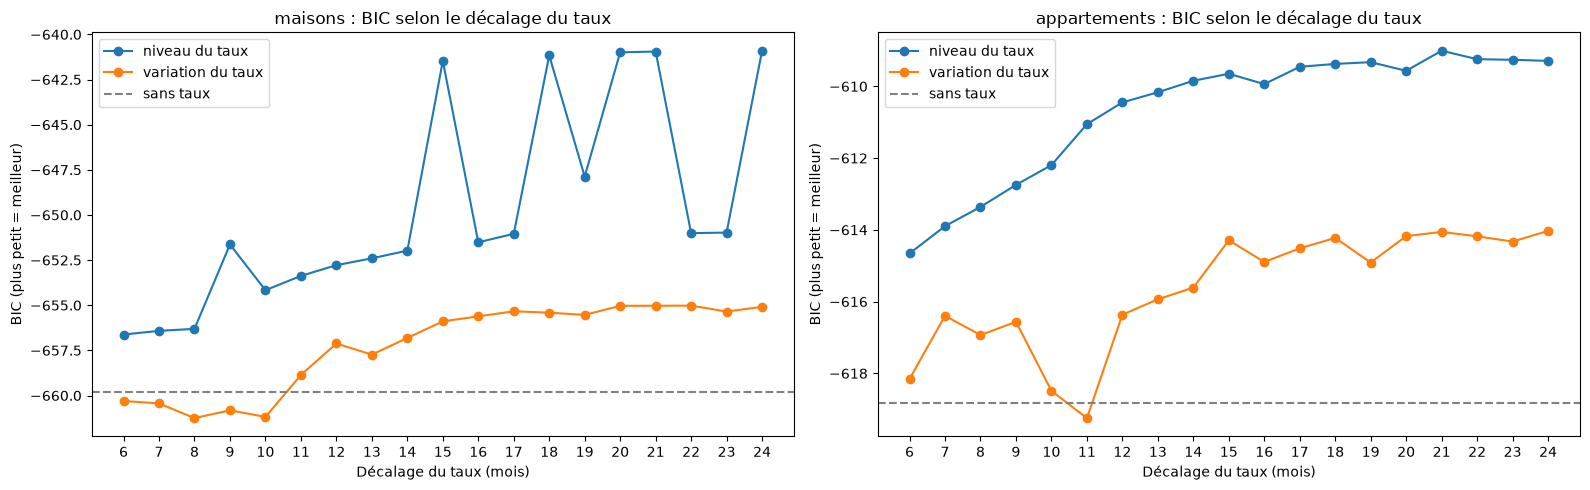

In [4]:
# 3.1 Recherche du délai d'effet du taux (6 à 24 mois), en niveau et en variation (train 2014-2023)
DECALAGES = range(6, 25)
ORDRE_EVOL = (ORDRE[0], 0, ORDRE[2])   # même modèle, appliqué à l'évolution du prix (déjà différenciée)
variation_taux = taux.diff()

lignes = []
for t in TYPES:
    evolution = np.log(prix[t].loc[:"2023"]).diff().dropna()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        ref = SARIMAX(evolution, order=ORDRE_EVOL, seasonal_order=SAISON).fit(disp=False, maxiter=ITERATIONS)
        lignes.append({"type de bien": t, "forme": "sans taux", "décalage (mois)": 0, "BIC": ref.bic,
                       "coef. du taux": np.nan, "p-valeur du taux": np.nan, "convergé": ref.mle_retvals["converged"]})
        for k in DECALAGES:
            # niveau : avec une constante (hausse moyenne) ; variation : sans constante, comme le modèle de référence
            for forme, exog, constante in [("niveau", taux.shift(k), "c"), ("variation", variation_taux.shift(k), None)]:
                m = SARIMAX(evolution, exog=exog.loc[evolution.index].rename("taux"), order=ORDRE_EVOL,
                            seasonal_order=SAISON, trend=constante).fit(disp=False, maxiter=ITERATIONS)
                lignes.append({"type de bien": t, "forme": forme, "décalage (mois)": k, "BIC": m.bic,
                               "coef. du taux": m.params["taux"], "p-valeur du taux": m.pvalues["taux"],
                               "convergé": m.mle_retvals["converged"]})
recherche = pd.DataFrame(lignes)
print("Modèles non convergés :", (~recherche["convergé"]).sum(), "sur", len(recherche))

# Meilleur décalage de chaque forme, comparé au modèle sans taux
meilleurs = (recherche[recherche["convergé"]].sort_values("BIC")
             .groupby(["type de bien", "forme"]).head(1).sort_values(["type de bien", "BIC"]))
display(meilleurs.round(3))

# Graphique : BIC selon le décalage ; ligne grise = modèle sans taux (un point sous la ligne = le taux aide)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, t in zip(axes, TYPES):
    r = recherche[recherche["type de bien"] == t]
    for forme in ["niveau", "variation"]:
        rf = r[r["forme"] == forme]
        ax.plot(rf["décalage (mois)"], rf["BIC"], marker="o", label=f"{forme} du taux")
    ax.axhline(r.loc[r["forme"] == "sans taux", "BIC"].iloc[0], color="grey", ls="--", label="sans taux")
    ax.set_title(f"{t} : BIC selon le décalage du taux")
    ax.set_xlabel("Décalage du taux (mois)")
    ax.set_ylabel("BIC (plus petit = meilleur)")
    ax.set_xticks(list(DECALAGES))
    ax.legend()
plt.tight_layout()
plt.show()

**Lecture**

Un point sous la ligne grise signifie que le taux améliore le modèle.
- **Niveau du taux** : quel que soit le décalage, le modèle est moins bon que sans taux.
- **Variation du taux** : elle améliore le modèle pour des décalages de 8 à 10 mois (maisons) et de 11 mois (appartements). Le coefficient est négatif et significatif (− 0,038 et − 0,043, p-valeur d'environ 0,02) : quand le taux monte, l'évolution des prix ralentit 8 à 11 mois plus tard.
- **Taille du gain** : très faible (1,5 point de BIC pour les maisons, 0,4 pour les appartements, moins de 2 points) : le signal existe, mais il est faible.

### 3.2 Validation croisée avec le taux

On reprend la validation croisée sur 5 plis avec le modèle de la partie 1, auquel on ajoute la forme et le décalage du taux retenus pour chaque type de bien. Pour prévoir les 12 mois, il faut connaître le taux des mois précédents : pour les mois pas encore connus au moment de la prévision, on suppose que le taux ne bouge plus (dernier niveau connu, ou variation nulle).

Retenu : {'appartements': ('variation', 11), 'maisons': ('variation', 8)}


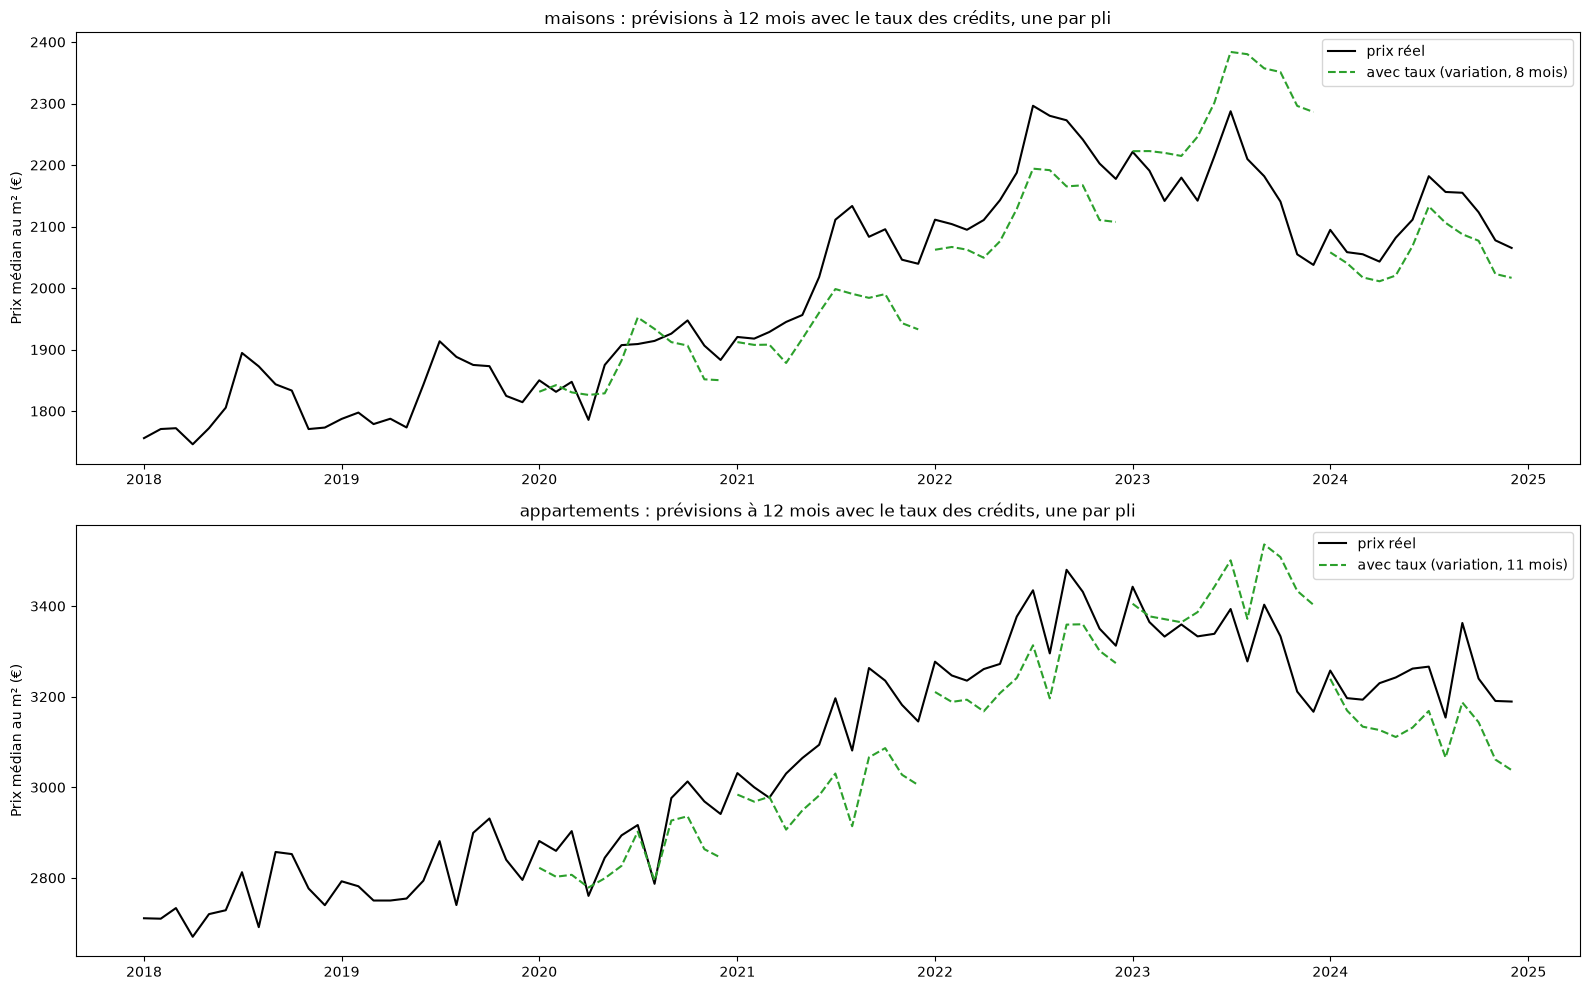

,type de bien,année prévue,MAE avec taux (€/m²),MAE sans taux (€/m²),convergé,gain du taux (%)
0,maisons,2020,30.3,31.9,True,5.1
1,maisons,2021,72.7,71.2,True,-2.1
2,maisons,2022,70.0,70.3,True,0.4
3,maisons,2023,123.3,116.0,True,-6.3
4,maisons,2024,45.4,11.1,True,-308.9
5,appartements,2020,57.8,60.9,True,5.2
6,appartements,2021,117.2,108.2,True,-8.3
7,appartements,2022,80.1,83.1,True,3.7
8,appartements,2023,101.5,127.4,True,20.3
9,appartements,2024,100.7,25.0,True,-303.6


Moyenne des 5 plis :


,MAE avec taux (€/m²),MAE sans taux (€/m²),gain du taux (%)
type de bien,,,
appartements,91.5,80.9,-13.0
maisons,68.3,60.1,-13.7


In [5]:
# 3.2 Validation croisée avec le taux (meilleure forme et meilleur décalage de 3.1), comparée au SARIMA sans taux
avec_taux = meilleurs[meilleurs["forme"] != "sans taux"].groupby("type de bien").head(1)
choix = {l["type de bien"]: (l["forme"], int(l["décalage (mois)"])) for _, l in avec_taux.iterrows()}
print("Retenu :", choix)

lignes = []
fig, axes = plt.subplots(2, 1, figsize=(16, 10))
for ax, t in zip(axes, TYPES):
    forme, k = choix[t]
    serie_log = np.log(prix[t])
    evolution = serie_log.diff()
    ax.plot(prix[t].loc["2018":], color="black", label="prix réel")
    for pli, (i_train, i_test) in enumerate(decoupage.split(prix[t])):
        fin, dates = prix[t].index[i_train[-1]], prix[t].index[i_test]

        # Taux connu à la fin du train ; après, on suppose qu'il ne bouge plus
        if forme == "niveau":
            connu, constante = taux.copy(), "c"
            connu.loc[connu.index > fin] = taux.loc[fin]
        else:
            connu, constante = variation_taux.copy(), None
            connu.loc[connu.index > fin] = 0
        exog = connu.shift(k).rename("taux")

        evol_train = evolution.loc[:fin].dropna().asfreq("MS")
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = SARIMAX(evol_train, exog=exog.loc[evol_train.index], order=ORDRE_EVOL, seasonal_order=SAISON,
                        trend=constante).fit(disp=False, maxiter=ITERATIONS)
        prevision = np.exp(serie_log.loc[fin] + m.forecast(steps=HORIZON, exog=exog.loc[dates]).cumsum())
        annee = dates.year[0]
        sarima = validation_prix[(validation_prix["type de bien"] == t) & (validation_prix["année prévue"] == annee)]
        lignes.append({"type de bien": t, "année prévue": annee,
                       "MAE avec taux (€/m²)": mean_absolute_error(prix[t].loc[dates], prevision),
                       "MAE sans taux (€/m²)": sarima["MAE modèle (€/m²)"].iloc[0],
                       "convergé": m.mle_retvals["converged"]})
        ax.plot(prevision, ls="--", color="tab:green", label=f"avec taux ({forme}, {k} mois)" if pli == 0 else None)
    ax.set_title(f"{t} : prévisions à 12 mois avec le taux des crédits, une par pli")
    ax.set_ylabel("Prix médian au m² (€)")
    ax.legend()
plt.tight_layout()
plt.show()

validation_taux = pd.DataFrame(lignes)
validation_taux["gain du taux (%)"] = (1 - validation_taux["MAE avec taux (€/m²)"] / validation_taux["MAE sans taux (€/m²)"]) * 100
display(validation_taux.round(1))
moy = validation_taux.groupby("type de bien")[["MAE avec taux (€/m²)", "MAE sans taux (€/m²)"]].mean()
moy["gain du taux (%)"] = (1 - moy["MAE avec taux (€/m²)"] / moy["MAE sans taux (€/m²)"]) * 100
print("Moyenne des 5 plis :")
display(moy.round(1))

**Lecture**

- **En moyenne, le taux dégrade la prévision** : l'erreur passe de 60 à 68 €/m² pour les maisons et de 81 à 92 €/m² pour les appartements (environ 13 % de plus).
- **De 2020 à 2022**, l'effet est presque nul : le taux a peu varié avant 2022, et le modèle n'a jamais vu de forte hausse ; il ne peut pas apprendre son effet.
- **En 2023**, le taux aide pour les appartements (erreur réduite de 20 %), pas pour les maisons (erreur augmentée de 6 %).
- **En 2024**, l'erreur est multipliée par environ 4 : le modèle a appris sur 2022-2023 qu'une hausse du taux fait baisser les prix et prévoit une nouvelle baisse, alors que les prix se stabilisent.

**Conclusion de la partie 3** : le lien entre le taux des crédits et les prix, montré par l'analyse exploratoire, existe : les prix réagissent aux variations du taux, 8 à 11 mois plus tard. Mais ce lien n'améliore pas la prévision du prix à un an, pour deux raisons : l'information apportée par le taux est en grande partie déjà contenue dans les prix des mois précédents, et son effet n'est pas stable dans le temps (fin 2024, un taux encore élevé ne fait plus baisser les prix). Le modèle sans taux est retenu.

## 4. Test final sur 2025

Le modèle retenu est réentraîné sur 2014-2024, puis prévoit les 12 mois de 2025 d'un seul coup. L'année 2025, utilisée à aucune étape précédente, est chargée seulement maintenant.

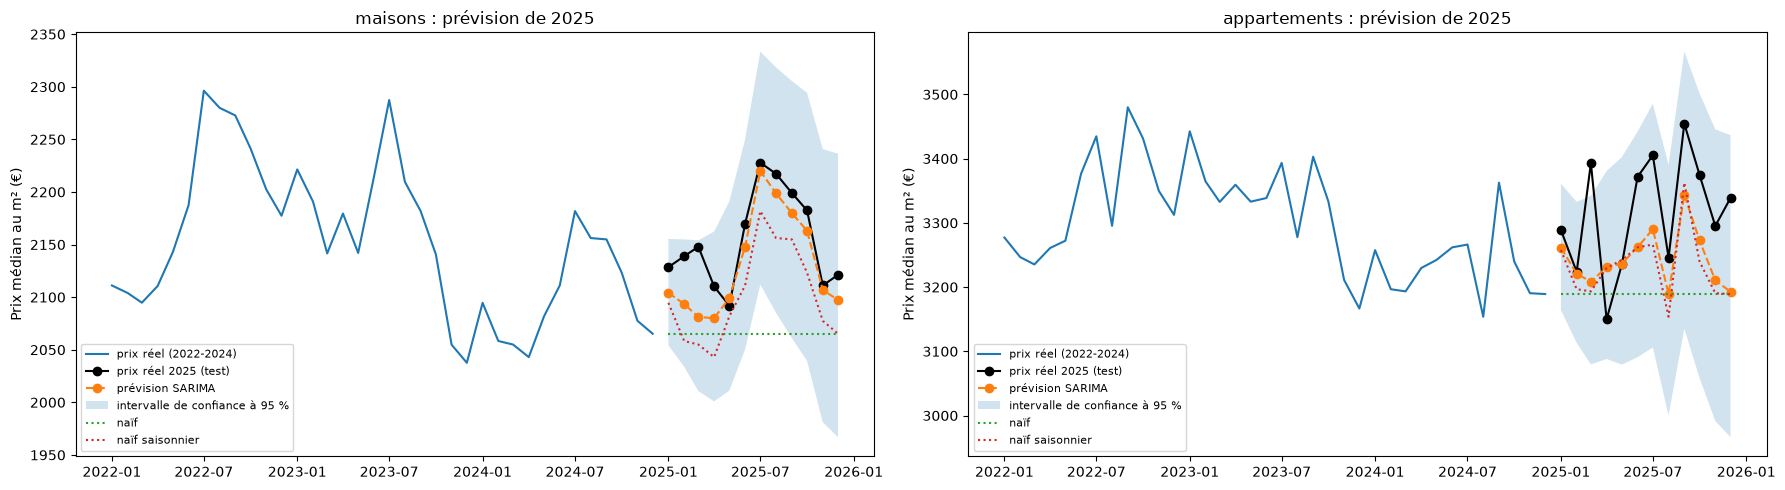

,mois évalués,MAE modèle (€/m²),MAPE modèle (%),MAE naïf (€/m²),MAE naïf saisonnier (€/m²),convergé,gain sur le naïf (%),gain sur le naïf saisonnier (%)
type de bien,,,,,,,,
maisons,12,24.1,1.1,88.6,53.6,True,72.8,55.1
appartements,12,85.2,2.5,132.1,97.2,True,35.5,12.4


In [6]:
# 4. Test final : prévision de 2025 par le SARIMA de la partie 1, réentraîné sur 2014-2024
reel_2025 = series_mensuelles([2025])

lignes = []
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, t in zip(axes, TYPES):
    reel = reel_2025.loc[t, "prix"]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        m = SARIMAX(np.log(prix[t]), order=ORDRE, seasonal_order=SAISON).fit(disp=False, maxiter=ITERATIONS)
    prev = m.get_forecast(steps=HORIZON)
    prevision = np.exp(prev.predicted_mean).loc[reel.index]
    ic = np.exp(prev.conf_int(alpha=0.05))
    naif = pd.Series(prix[t].iloc[-1], index=reel.index)                     # décembre 2024 répété
    naif_saison = pd.Series(prix[t].loc["2024"].values, index=prev.predicted_mean.index).loc[reel.index]
    lignes.append({"type de bien": t, "mois évalués": len(reel),
                   "MAE modèle (€/m²)": mean_absolute_error(reel, prevision),
                   "MAPE modèle (%)": mean_absolute_percentage_error(reel, prevision) * 100,
                   "MAE naïf (€/m²)": mean_absolute_error(reel, naif),
                   "MAE naïf saisonnier (€/m²)": mean_absolute_error(reel, naif_saison),
                   "convergé": m.mle_retvals["converged"]})

    ax.plot(prix[t].loc["2022":], label="prix réel (2022-2024)")
    ax.plot(reel, color="black", marker="o", label="prix réel 2025 (test)")
    ax.plot(prevision, ls="--", marker="o", label="prévision SARIMA")
    ax.fill_between(ic.index, ic.iloc[:, 0], ic.iloc[:, 1], alpha=0.2, label="intervalle de confiance à 95 %")
    ax.plot(naif, ls=":", label="naïf")
    ax.plot(naif_saison, ls=":", label="naïf saisonnier")
    ax.set_title(f"{t} : prévision de 2025")
    ax.set_ylabel("Prix médian au m² (€)")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

test_final = pd.DataFrame(lignes).set_index("type de bien")
test_final["gain sur le naïf (%)"] = (1 - test_final["MAE modèle (€/m²)"] / test_final["MAE naïf (€/m²)"]) * 100
test_final["gain sur le naïf saisonnier (%)"] = (1 - test_final["MAE modèle (€/m²)"] / test_final["MAE naïf saisonnier (€/m²)"]) * 100
display(test_final.round(1))

**Lecture**

- **Le modèle bat les deux références naïves** : erreur de 24 €/m² (1,1 %) pour les maisons et de 85 €/m² (2,5 %) pour les appartements ; gain de 73 % et 36 % sur la prévision naïve, de 55 % et 12 % sur la prévision naïve saisonnière.
- **L'erreur est conforme à la validation croisée** (2,9 % et 2,5 % en moyenne). Le seul résultat de 2024 (0,5 à 0,8 %) aurait donné une idée trop optimiste de la qualité du modèle.
- **Les prix remontent légèrement en 2025** : les prix réels sont le plus souvent au-dessus de la prévision, surtout pour les appartements à partir de mai. Comme en 2020-2022, le modèle sous-estime une hausse. Le taux des crédits a baissé au cours de 2024 : cette remontée est cohérente avec le délai de 8 à 11 mois trouvé en partie 3 (hypothèse ; 2025 n'a pas servi à modifier le modèle).

## Conclusion

**La série des prix suffit-elle à prévoir l'évolution des prix ?** En grande partie, oui, quand le marché est stable : un SARIMA mensuel sur le seul prix médian prévoit l'année suivante avec 1 à 3 % d'erreur, et fait toujours mieux que les références naïves en moyenne (test final sur 2025 : 1,1 % pour les maisons, 2,5 % pour les appartements). En revanche, il ne voit pas venir les changements de tendance : il sous-estime les hausses et surestime au moment d'un retournement, comme en 2023.

**Le volume de ventes et le taux des crédits** aident à comprendre ces retournements : le taux change, le volume de ventes réagit, puis le prix suit, plusieurs mois plus tard (hypothèse d'enchaînement). Mais aucune de ces deux informations n'améliore la prévision du prix en moyenne : elles aident l'année du retournement et pénalisent les années calmes, car leur effet n'est pas stable dans le temps.

**Pour la modélisation principale** (une ligne par bassin de vie et par année), le taux des crédits reste une variable candidate : le modèle n'y dispose pas des prix des mois précédents, qui contiennent ici déjà l'essentiel de l'information.